# Why Did Sri Lanka's Solar-Heavy Grid Collapse in 2025, and What Would Prevent It?

## 1. Summary

On 9 February 2025 a short fault at one substation in Sri Lanka was cleared in about one second, yet the whole island lost power 22 seconds later. This notebook builds a small model of the grid frequency during those seconds: two ordinary differential equations (the swing equation and a governor), solved with a fourth-order Runge-Kutta method, plus threshold rules for rooftop-solar inverters and for the automatic load-shedding scheme. The model is checked against exact solutions, calibrated to the seven recorded frequency values, and then used in a Monte Carlo study to ask which single change would have kept the grid alive.

**Main result.** Among the Monte Carlo runs that reproduce the recorded frequency, every one collapses as the real grid did. Correcting the inverter settings, delivering the spinning reserve that existed on paper, load shedding that does not also remove rooftop solar, or a fast battery of about 36 MW each prevent the collapse in all of those runs (95% interval 0 to 0.6%). Extra inertia does not: with 50% more stored energy every run still collapses, only later (at 24.9 s instead of 16.3 s in the calibrated case). Across the full range of the uncertain inputs, the weak relief given by load shedding is the input that drives the outcome most.

**Main evidence that the numbers are right.** With the events switched off, the RK4 solution matches the exact exponential solution to within 1e-9 Hz, and the measured error order is 4.0 for RK4 and 1.0 for Euler. With the events on, the energy-balance residual is below 1e-4, the calibrated model matches the seven recorded frequency values with a root-mean-square error of 0.12 Hz, and the Monte Carlo error falls with the expected slope of about -1/2.

## 2. Problem and question

**What happened.** At 11:13:39 on Sunday 9 February 2025 a monkey touched a 33 kV busbar at the Panadura grid substation. Protection cleared the fault within about 1.1 seconds, and no large power station failed at that moment. Even so, the system frequency slid from 50.12 Hz to 43.48 Hz in 18.7 seconds, the remaining generators tripped, and the island was dark for about four and a half hours [1], [2].

**Why it is disputed.** About half of the 1,489 MW being generated came from sources embedded in the distribution network, mostly rooftop solar [1]. The published investigations point to several weaknesses and weigh them differently [2], [3]:

- **Inverter settings.** A survey of 1,608 rooftop inverters found 41% set to disconnect above the prescribed 47 Hz, some as high as 49.5 Hz [2].
- **Load shedding.** The automatic scheme switched off feeders that were also carrying rooftop solar, so each stage removed generation as well as load [1], [3].
- **Generator response.** The unit controlling frequency raised its output slowly [2].
- **Low inertia.** With little conventional plant running, the frequency fell quickly [3].

**The question.** Which of these four factors mattered most, and which single fix would have prevented the collapse?

**Why it matters.** Sri Lanka has committed to 70% renewable electricity by 2030 [9], so the grid will run in this solar-heavy condition more often.

**Scope.** One frequency for the whole island (a single-bus model). Voltage and network flows are not modelled.

## 3. Model, assumptions and equations

### 3.1 State variables and equations

The model tracks three quantities over time $t$ (seconds, measured from 11:13:40.0, the first recorded value):

| Symbol | Meaning | Unit |
|---|---|---|
| $f$ | system frequency | Hz |
| $P_g$ | extra mechanical power from the governor of the frequency-controlling unit | MW |
| $P_b$ | power from a grid battery (zero unless a battery is being tested) | MW |

**Frequency (swing equation).** Frequency falls when generation is less than load. The kinetic energy stored in the spinning machines, $E_k$, sets how fast [4], [5].

$$\frac{df}{dt} = \frac{f_0}{2E_k}\Big(u(t) + P_g + P_b - D\,(f - f_{init})\Big)$$

**Governor.** The controlling unit adds power in proportion to the frequency drop, with a lag and an upper limit.

$$\frac{dP_g}{dt} = \frac{1}{T_g}\Big(\min\big(P_{cap},\; K\,\max(f_0 - f,\,0)\big) - P_g\Big)$$

**Battery (only in the battery experiments).** A fast droop response that reaches full power $P_{bat}$ when the frequency is $\Delta f_b$ below $f_b$.

$$\frac{dP_b}{dt} = \frac{1}{\tau_b}\Big(\mathrm{clip}\big(\tfrac{P_{bat}}{\Delta f_b}(f_b - f),\,0,\,P_{bat}\big) - P_b\Big)$$

| Symbol | Meaning | Unit | Value | Basis |
|---|---|---|---|---|
| $f_0$ | nominal frequency | Hz | 50 | system standard |
| $f_{init}$ | frequency at $t=0$ | Hz | 50.12 | recorded [1] |
| $E_k$ | stored kinetic energy ($H \times S$) | MW s | calibrated | compared with unit data [3] |
| $D$ | load damping | MW/Hz | calibrated in 30 to 60 | 1 to 2% load change per 1% frequency change |
| $K$, $T_g$, $P_{cap}$ | governor gain, lag, limit | MW/Hz, s, MW | fitted | recorded unit output [1] |
| $u(t)$ | net change in generation minus load since $t=0$ | MW | from the event rules | see 3.2 |

### 3.2 Event rules (they change $u$ between time steps)

$$u(t) = -\underbrace{\Delta P_0}_{\text{first solar loss}} \;-\; \underbrace{(P_{emb} - \Delta P_0)\,F(f_{min})}_{\text{inverters tripped by frequency}} \;+\; \underbrace{r \sum_{i\,\in\,\text{fired}} L_i}_{\text{net load-shedding relief}}$$

1. **First solar loss $\Delta P_0$.** Rooftop inverters near the fault disconnected because of the voltage dip. A frequency-only model cannot simulate a voltage dip, so this loss is *injected* as a step. Its size is uncertain: 25 MW [1] to 77 MW [2].
2. **Inverter trips by frequency, $F(f_{min})$.** $F$ is the share of the remaining embedded pool ($P_{emb} \approx 750$ MW) that has disconnected once the frequency has been as low as $f_{min}$. From the inverter survey [2]: 11% trip at 49.5 Hz, 18% are spread between 49.5 and 48 Hz, 12% between 48 and 47 Hz, and 59% at 47 Hz. *Assumption:* megawatts follow the share of surveyed inverters.
3. **Load shedding.** Five under-frequency stages and a rate-of-change stage, each with its threshold, time delay and megawatts $L_i$ [1], [3]. Each shed feeder also takes its rooftop solar with it, so only a fraction $r$ (the *relief factor*) of the nominal megawatts is real relief.
4. **Governor limit.** $P_{cap}$ is fitted to what the controlling unit actually delivered, not to the 230 MW of spinning reserve on paper.

**Collapse rule.** A run counts as a collapse if the frequency falls below 47.0 Hz, where the last 59% of inverters disconnect. The test is repeated with 46.0 Hz.

### 3.3 Main assumptions

1. One frequency for the whole island; no voltage or network.
2. Load damping is linear in frequency and does not shrink as load is shed.
3. Inverters disconnect as soon as their setting is reached and do not reconnect within the 20 s window.
4. Rooftop megawatts are spread across settings in the same proportions as the surveyed inverters.
5. The model is not expected to be exact in the last two to three seconds, when generator protection (outside the model) takes over.

### 3.4 Concepts used

| Concept | Where it is used |
|---|---|
| Numerical ODE solvers (Euler, RK4, measured error order) | Sections 4.2 and 5 |
| Input modelling and random variate generation (inverse-transform sampling from an empirical distribution) | Sections 4.4 and 6.3 |
| Monte Carlo estimation and the law of large numbers (confidence intervals, $N^{-1/2}$ error) | Sections 6.3 to 6.8 |

## 4. Implementation

### 4.1 Set-up, seeds and data

In [1]:
# Setup: everything used here is already installed on Colab; the line below is a no-op there.
!pip install -q numpy scipy matplotlib
import csv
import io
import os
import time
import urllib.request

import numpy as np
import scipy
import matplotlib
import matplotlib.pyplot as plt
from scipy.linalg import expm
from scipy.interpolate import PchipInterpolator

T_START, CPU_START = time.time(), time.process_time()
SEED = 20250209                      # one seed for every random draw in this notebook
print("numpy", np.__version__, "| scipy", scipy.__version__, "| matplotlib", matplotlib.__version__)
print("random seed:", SEED)

os.makedirs("figures", exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})
BLUE, ORANGE, GREEN, RED, GREY = "#1f6f8b", "#d9822b", "#2e8b57", "#c0392b", "#6b7280"


[notice] A new release of pip is available: 26.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


numpy 2.4.6 | scipy 1.18.0 | matplotlib 3.11.1
random seed: 20250209


In [2]:
# Data: read from the public repository, with a copy next to the notebook as a fallback.
DATA_URL = "https://raw.githubusercontent.com/vinuki-thiranya/Power-System-Frequency-Stability/main/data/"


def read_table(name):
    """Return the rows of a CSV file as a list of dictionaries."""
    try:
        with urllib.request.urlopen(DATA_URL + name, timeout=20) as reply:
            text, origin = reply.read().decode("utf-8"), "repository"
    except Exception:
        for folder in ("data", "../data", "Data", "../Data"):
            path = os.path.join(folder, name)
            if os.path.exists(path):
                with open(path, encoding="utf-8") as handle:
                    text, origin = handle.read(), "local copy"
                break
        else:
            raise
    print(f"loaded {name} from the {origin}")
    return list(csv.DictReader(io.StringIO(text)))


PAR = {row["name"]: float(row["value"]) for row in read_table("parameters.csv")}
record = read_table("recorded_frequency.csv")
REC_T = np.array([float(r["time_s"]) for r in record])              # [s] since 11:13:40.0
REC_F = np.array([float(r["frequency_hz"]) for r in record])        # [Hz]
REC_PU = np.array([float(r["victoria_u2_mw"]) for r in record])     # [MW] output of the controlling unit
EVENTS = {r["event"]: float(r["time_s"]) for r in read_table("recorded_events.csv")}   # [s] recorder times
UNITS = read_table("unit_inertia.csv")

# Load-shedding stages: threshold [Hz], delay [s], load [MW], uses under-frequency?, uses rate-of-change?
STAGES = []
for row in read_table("ufls_stages.csv"):
    uses_uf = row["threshold_hz"] != ""
    STAGES.append((float(row["threshold_hz"]) if uses_uf else None,
                   float(row["delay_s"]) if uses_uf else None,
                   float(row["load_mw"]), uses_uf, row["rocof_element"] == "yes", row["stage"]))
print("load-shedding stages:", [(s[5], s[2]) for s in STAGES], "total", round(sum(s[2] for s in STAGES), 1), "MW")

F0 = PAR["f0"]                        # [Hz] nominal frequency
F_INIT = PAR["f_init"]                # [Hz] first recorded value
F_HIGH, F_MID, F_LOW = PAR["f_trip_high"], PAR["f_trip_mid"], PAR["f_trip_low"]     # [Hz] inverter band edges
COUNTS = np.array([PAR["count_49_5"], PAR["count_48_49_5"], PAR["count_47_48"], PAR["count_47"]])
N_INV = int(PAR["n_inverters"])
SHARES = COUNTS / N_INV               # share of inverters at each setting, highest setting first
assert COUNTS.sum() == N_INV
print("inverter shares (49.5 Hz, 48 to 49.5, 47 to 48, 47 Hz):", np.round(SHARES, 4))

DT = 0.01                             # [s] time step: divides the 100 ms and 500 ms relay delays exactly
T_END = 20.0                          # [s] simulated window
F_COLLAPSE = PAR["f_collapse"]        # [Hz] collapse rule
F_FLOOR = 40.0                        # [Hz] traces are not followed below this (generators trip by here)

loaded parameters.csv from the repository
loaded recorded_frequency.csv from the repository


loaded recorded_events.csv from the repository


loaded unit_inertia.csv from the repository


loaded ufls_stages.csv from the repository
load-shedding stages: [('I', 65.4), ('II', 58.5), ('III', 65.7), ('IV', 75.2), ('V', 5.8), ('V_or_dfdt', 23.2), ('dfdt', 112.3)] total 406.1 MW
inverter shares (49.5 Hz, 48 to 49.5, 47 to 48, 47 Hz): [0.1101 0.1754 0.1219 0.5927]


### 4.2 The two equations and the time-steppers

`rhs` is the right-hand side of the equations in 3.1. It works on single numbers and on NumPy arrays alike, so the same code runs one case or thousands of cases at once. `step_euler` and `step_rk4` advance the state by one time step with the net power change `u` held constant during the step.

In [3]:
def rhs(t, y, u, p):
    """Rates of change of the state y = (f, Pg, Pb).

    f  [Hz]  system frequency
    Pg [MW]  extra governor power
    Pb [MW]  battery power
    u  [MW]  net change in generation minus load since t = 0 (negative = shortfall)
    Returns (df/dt [Hz/s], dPg/dt [MW/s], dPb/dt [MW/s]).
    """
    f, Pg, Pb = y
    dfdt = (u + Pg + Pb - p["D"] * (f - p["f_init"])) / p["M"]          # swing equation, M = 2 Ek / f0
    target = np.minimum(p["Pcap"], p["K"] * np.maximum(p["f0"] - f, 0.0))   # [MW] droop with a limit
    dPg = (target - Pg) / p["Tg"]                                        # governor lag
    b_target = np.clip(p["Kb"] * (p["f_b"] - f), 0.0, p["Pbat"])         # [MW] battery droop, Kb = Pbat / df_b
    dPb = (b_target - Pb) / p["tau_b"]                                   # battery response time
    return np.array([dfdt, dPg, dPb])


def step_euler(fun, t, y, dt, u, p):
    """One explicit Euler step (first-order accurate)."""
    return y + dt * fun(t, y, u, p)


def step_rk4(fun, t, y, dt, u, p):
    """One classical Runge-Kutta step (fourth-order accurate)."""
    k1 = fun(t, y, u, p)
    k2 = fun(t + 0.5 * dt, y + 0.5 * dt * k1, u, p)
    k3 = fun(t + 0.5 * dt, y + 0.5 * dt * k2, u, p)
    k4 = fun(t + dt, y + dt * k3, u, p)
    return y + dt / 6.0 * (k1 + 2.0 * k2 + 2.0 * k3 + k4)


def make_params(n=1, **changes):
    """Parameter set for n runs. Every value becomes an array of length n."""
    base = dict(
        Ek=6000.0,              # [MW s]  stored kinetic energy (replaced by the calibrated value in 6.1)
        D=40.0,                 # [MW/Hz] load damping
        K=12.0,                 # [MW/Hz] governor gain
        Tg=2.0,                 # [s]     governor lag
        Pcap=PAR["governor_cap"],   # [MW] largest extra governor power
        dP0=40.0,               # [MW]    first solar loss (voltage-driven, injected)
        t_loss=PAR["t_loss"],   # [s]     time of the first loss
        Pemb=PAR["P_embedded"], # [MW]    embedded generation that can trip
        s1=SHARES[0],           # [-]     share of inverters set at 49.5 Hz
        s2=SHARES[1],           # [-]     share set between 48 and 49.5 Hz
        s3=SHARES[2],           # [-]     share set between 47 and 48 Hz (the rest trip at 47 Hz)
        relief=0.5,             # [-]     share of each shed block that is real load relief
        Pbat=0.0,               # [MW]    battery size (0 = no battery)
        tau_b=0.25,             # [s]     battery response time
        f_b=PAR["battery_f_start"],     # [Hz] battery starts responding below this
        df_b=PAR["battery_df_full"],    # [Hz] full battery power this far below f_b
        f_init=F_INIT, f0=F0)   # [Hz]
    base.update(changes)
    return {k: np.broadcast_to(np.asarray(v, dtype=float), (n,)).copy() for k, v in base.items()}


def prepared(p):
    """Add the two derived constants the equations use: M [MW s/Hz] and the battery droop Kb [MW/Hz]."""
    return dict(p, M=2.0 * p["Ek"] / p["f0"], Kb=p["Pbat"] / p["df_b"])


def simulate_smooth(p, u, T, dt, stepper=step_rk4):
    """Integrate the equations with a constant power change u and no event rules.

    Returns the times [s] and the states, shape (steps + 1, 3, n)."""
    p = prepared(p)
    n_steps = int(round(T / dt))
    y = np.array([p["f_init"].copy(), np.zeros_like(p["Ek"]), np.zeros_like(p["Ek"])])
    out = np.empty((n_steps + 1,) + y.shape)
    out[0] = y
    for k in range(n_steps):
        y = stepper(rhs, k * dt, y, dt, u, p)
        out[k + 1] = y
    return np.arange(n_steps + 1) * dt, out

### 4.3 The event model

`simulate_events` adds the four rules of section 3.2. At the start of every time step it looks at the present frequency, decides which inverters have tripped and which load-shedding stages fire, updates the net power change `u`, and then takes one step with `u` held constant. Because `DT` divides 100 ms and 500 ms exactly, every relay delay is an exact number of steps.

All runs are advanced together as NumPy arrays (one array element per run), which is what makes the Monte Carlo study fast.

In [4]:
ROCOF_LIMIT, ROCOF_ARM, ROCOF_DELAY = PAR["rocof_limit"], PAR["rocof_arm"], PAR["rocof_delay"]   # [Hz/s], [Hz], [s]
ST_THRESHOLD = np.array([[s[0] if s[3] else -np.inf] for s in STAGES])    # [Hz] under-frequency threshold
ST_DELAY = np.array([[s[1] if s[3] else 0.0] for s in STAGES])           # [s]  time delay
ST_LOAD = np.array([[s[2]] for s in STAGES])                             # [MW] load shed by the stage
ST_ROCOF = np.array([[s[4]] for s in STAGES])                            # also fires on the rate-of-change element?
SETTLED = 0.002          # [Hz/s] a run falling more slowly than this is no longer "falling"
CALM_TIME = 5.0          # [s]    it must stay that way this long to count as settled
STOP_BELOW = 45.0        # [Hz]   a run below this is beyond recovery under either collapse rule


def trip_fraction(fmin, p):
    """Share of the embedded pool that has disconnected once frequency has been as low as fmin [Hz]."""
    band2 = p["s2"] * np.clip((F_HIGH - fmin) / (F_HIGH - F_MID), 0.0, 1.0)   # spread between 49.5 and 48 Hz
    band3 = p["s3"] * np.clip((F_MID - fmin) / (F_MID - F_LOW), 0.0, 1.0)     # spread between 48 and 47 Hz
    frac = np.where(fmin <= F_HIGH, p["s1"] + band2 + band3, 0.0)
    return np.where(fmin <= F_LOW, 1.0, frac)                                 # everything is off at 47 Hz


def simulate_events(p, T=T_END, dt=DT, stepper=step_rk4, keep_trace=False, sample_times=(),
                    levels=(49.5, 47.5, 47.0), stop_when_settled=False):
    """Run the full model for every parameter set in p at once.

    Returns a dictionary with, for each run: the lowest frequency, whether it was still falling at the end,
    the times at which the frequency first fell below each level, the firing time of each load-shedding
    stage, and (optionally) full traces. With stop_when_settled the loop ends as soon as every run has
    either gone below STOP_BELOW or stopped falling for CALM_TIME seconds."""
    p = prepared(p)
    n = p["Ek"].size
    n_steps = int(round(T / dt))
    y = np.array([p["f_init"].copy(), np.zeros(n), np.zeros(n)])        # f [Hz], Pg [MW], Pb [MW]
    fmin = y[0].copy()                                                   # [Hz] lowest frequency so far
    n_stage = len(STAGES)
    t_uf = np.full((n_stage, n), np.nan)        # [s] when each stage first saw its frequency condition
    fired = np.zeros((n_stage, n), dtype=bool)
    t_fire = np.full((n_stage, n), np.nan)      # [s] when each stage fired
    t_rc = np.full(n, np.nan)                   # [s] when the rate-of-change condition was first seen
    shed = np.zeros(n)                          # [MW] nominal load shed so far
    pool = p["Pemb"] - p["dP0"]                 # [MW] embedded generation still able to trip on frequency
    calm = np.zeros(n)                          # [s] how long the run has not been falling
    check_every = int(round(0.5 / dt))          # settle test every 0.5 s
    t_cross = {lv: np.full(n, np.nan) for lv in levels}
    sample_at = {int(round(ts / dt)): i for i, ts in enumerate(sample_times)}
    samp_f = np.zeros((len(sample_times), n))
    samp_pg = np.zeros((len(sample_times), n))
    samp_dfdt = np.zeros((len(sample_times), n))
    if keep_trace:
        trace = {key: np.zeros((n_steps + 1, n)) for key in ("f", "Pg", "Pb", "u", "lost", "shed")}

    for k in range(n_steps + 1):
        t = k * dt
        f = y[0]
        # Rules 1 and 2: solar lost so far
        lost = np.where(t >= p["t_loss"], p["dP0"], 0.0) + pool * trip_fraction(fmin, p)   # [MW]
        u = -lost + p["relief"] * shed                                                      # [MW]
        dfdt = (u + y[1] + y[2] - p["D"] * (f - p["f_init"])) / p["M"]                      # [Hz/s]
        # Rule 3: load shedding. A stage fires once its condition has held for its delay.
        rc_now = (f < ROCOF_ARM) & (dfdt < -ROCOF_LIMIT)
        t_rc = np.where(rc_now, np.where(np.isnan(t_rc), t, t_rc), np.nan)
        rc_trip = (t - t_rc) >= ROCOF_DELAY - 1e-9
        below = f <= ST_THRESHOLD                                    # shape (stages, runs)
        t_uf = np.where(below, np.where(np.isnan(t_uf), t, t_uf), np.nan)
        go = (((t - t_uf) >= ST_DELAY - 1e-9) | (ST_ROCOF & rc_trip)) & ~fired
        if go.any():
            fired |= go
            t_fire = np.where(go, t, t_fire)
            shed = shed + (go * ST_LOAD).sum(axis=0)
            u = -lost + p["relief"] * shed
            dfdt = (u + y[1] + y[2] - p["D"] * (f - p["f_init"])) / p["M"]
        if k in sample_at:
            samp_f[sample_at[k]], samp_pg[sample_at[k]], samp_dfdt[sample_at[k]] = f, y[1], dfdt
        if keep_trace:
            for key, value in (("f", f), ("Pg", y[1]), ("Pb", y[2]), ("u", u), ("lost", lost), ("shed", shed)):
                trace[key][k] = value
        if k % check_every == 0:
            calm = np.where(dfdt >= -SETTLED, calm + 0.5, 0.0)
            if stop_when_settled and np.all((fmin < STOP_BELOW) | (calm >= CALM_TIME)):
                break
        if k == n_steps:
            break
        y = stepper(rhs, t, y, dt, u, p)                # one step with u held constant
        y[0] = np.maximum(y[0], F_FLOOR)
        fmin = np.minimum(fmin, y[0])
        for lv in levels:
            new = np.isnan(t_cross[lv]) & (y[0] < lv)
            t_cross[lv][new] = t + dt

    out = dict(fmin=fmin, falling_end=dfdt < -SETTLED, t_cross=t_cross, t_fire=t_fire, shed=shed, lost=lost,
               samp_f=samp_f, samp_pg=samp_pg, samp_dfdt=samp_dfdt, t_stop=t)
    if keep_trace:
        out["trace"] = trace
        out["t"] = np.arange(n_steps + 1) * dt
    return out

### 4.4 Statistics helpers

- `wilson_interval` gives the 95% confidence interval for a probability estimated from $k$ collapses in $N$ runs. Unlike the usual normal formula it behaves properly when the estimate is 0 or 1 [8]:

$$\frac{\hat{p} + \dfrac{z^2}{2N}}{1 + \dfrac{z^2}{N}} \;\pm\; \frac{z}{1 + \dfrac{z^2}{N}}\sqrt{\frac{\hat{p}(1-\hat{p})}{N} + \frac{z^2}{4N^2}}, \qquad z = 1.96$$

- `sample_inverter_shares` treats the 1,608 surveyed inverters as a sample, not a census. For each Monte Carlo run it draws 1,608 new inverters by **inverse-transform sampling**: a uniform random number $U$ is mapped through the inverse of the empirical cumulative distribution of the four settings. The shares in that redrawn sample are then used for the run.

In [5]:
def wilson_interval(k, n, z=1.96):
    """95% Wilson score interval for a proportion k/n. Returns (low, high)."""
    k, n = np.asarray(k, dtype=float), np.asarray(n, dtype=float)
    phat = k / n
    denom = 1.0 + z * z / n
    centre = (phat + z * z / (2.0 * n)) / denom
    half = z * np.sqrt(phat * (1.0 - phat) / n + z * z / (4.0 * n * n)) / denom
    return np.clip(centre - half, 0.0, 1.0), np.clip(centre + half, 0.0, 1.0)


def sample_inverter_shares(n_runs, rng, chunk=2000):
    """Redraw the inverter survey for each run. Returns shares with shape (n_runs, 4)."""
    cdf = np.cumsum(SHARES)                              # empirical cumulative distribution of the settings
    cdf[-1] = 1.0
    out = np.empty((n_runs, 4))
    for start in range(0, n_runs, chunk):
        m = min(chunk, n_runs - start)
        uniform = rng.random((m, N_INV))                 # U ~ Uniform(0, 1), one per inverter
        setting = np.searchsorted(cdf, uniform, side="right")   # inverse transform: U -> setting 0..3
        for j in range(4):
            out[start:start + m, j] = (setting == j).mean(axis=1)
    return out


def describe(k, n):
    low, high = wilson_interval(k, n)
    return f"{k / n:6.1%}  [95% CI {low:.1%} to {high:.1%}]  ({int(k)} of {int(n)})"

## 5. Verification

Verification asks *"does the code solve the equations correctly?"* It is kept separate from calibration (section 6.1), which asks *"do the equations match the real event?"* Every check below ends in an `assert`, so the notebook stops if one fails.

| Check | What is compared | Why it is a good test |
|---|---|---|
| 1. Exact solution | governor off, step loss: simulated $f(t)$ against the exponential formula | an independent closed-form answer |
| 2. Limiting cases | no loss; no damping; first-step slope | simple cases whose answer is known without any solver |
| 3. Error order | error against step size for the two-equation system | shows the solver converges at its theoretical rate (4 for RK4, 1 for Euler) |
| 4. Energy balance | time integral of the power imbalance against the change in stored energy | a conservation check that also covers the event rules |
| 5. Full-model step-size study | results at several step sizes against a much finer run | shows what the chosen step size costs once events are included |
| 6. Statistics helpers | Wilson interval and the inverse-transform sampler against known values | the Monte Carlo results depend on them |

### Check 1: exact solution

With the governor off and a constant loss $\Delta P$, the frequency equation is linear and has the solution

$$f(t) = f_{init} - \frac{\Delta P}{D}\left(1 - e^{-t/\tau}\right), \qquad \tau = \frac{2E_k}{f_0\,D}$$

In [6]:
def check_exact_solution(verbose=True):
    p = make_params(1, K=0.0, Ek=6000.0, D=40.0)        # governor off
    dP = 50.0                                            # [MW] step loss
    t, y = simulate_smooth(p, -dP, T=20.0, dt=DT, stepper=step_rk4)
    tau = 2.0 * 6000.0 / (F0 * 40.0)                     # [s]
    exact = F_INIT - dP / 40.0 * (1.0 - np.exp(-t / tau))
    err_rk4 = np.max(np.abs(y[:, 0, 0] - exact))
    _, y_e = simulate_smooth(p, -dP, T=20.0, dt=DT, stepper=step_euler)
    err_euler = np.max(np.abs(y_e[:, 0, 0] - exact))
    assert err_rk4 < 1e-9, f"RK4 differs from the exact solution by {err_rk4:.2e} Hz"
    assert err_euler < 1e-2
    if verbose:
        print(f"PASS check 1: largest RK4 error {err_rk4:.1e} Hz (tolerance 1e-9); Euler error {err_euler:.1e} Hz")
    return t, y[:, 0, 0], exact, err_rk4


t1, f1, exact1, _ = check_exact_solution()

PASS check 1: largest RK4 error 7.1e-14 Hz (tolerance 1e-9); Euler error 3.8e-04 Hz


### Check 2: limiting cases

- No loss: the frequency must stay exactly where it started.
- First instant: before damping or the governor can act, the slope must be $\left.\dfrac{df}{dt}\right|_{t=0} = -\dfrac{f_0\,\Delta P}{2E_k}$.
- No damping and no governor: the frequency must fall in a straight line with that slope.

In [7]:
def check_limits(verbose=True):
    p = make_params(1, Ek=6000.0, D=40.0)
    _, y = simulate_smooth(p, 0.0, T=20.0, dt=DT)
    drift = np.max(np.abs(y[:, 0, 0] - F_INIT))
    assert drift == 0.0, "frequency moved with zero imbalance"

    dP = 50.0
    slope_exact = -F0 * dP / (2.0 * 6000.0)                               # [Hz/s]
    y0 = np.array([p["f_init"], np.zeros(1), np.zeros(1)])
    slope_rhs = rhs(0.0, y0, -dP, prepared(p))[0, 0]
    assert abs(slope_rhs - slope_exact) < 1e-12

    q = make_params(1, Ek=6000.0, D=0.0, K=0.0)                           # no damping, no governor
    t, yq = simulate_smooth(q, -dP, T=10.0, dt=DT)
    line_err = np.max(np.abs(yq[:, 0, 0] - (F_INIT + slope_exact * t)))
    assert line_err < 1e-10
    if verbose:
        print(f"PASS check 2: drift with no loss = {drift:.1e} Hz; first slope {slope_rhs:.6f} Hz/s "
              f"= formula {slope_exact:.6f} Hz/s; straight-line error {line_err:.1e} Hz")


check_limits()

PASS check 2: drift with no loss = 0.0e+00 Hz; first slope -0.208333 Hz/s = formula -0.208333 Hz/s; straight-line error 1.9e-12 Hz


### Check 3: error order on the smooth problem

With the governor on but no limit and no events, the two equations form a linear system $\dot{x} = Ax + b$ with $x = (f - f_{init},\, P_g)$. Its exact solution is $x(T) = e^{AT}\,(x_0 + A^{-1}b) - A^{-1}b$, computed here with a matrix exponential, independently of the time-steppers.

The step size is halved five times. On a log-log plot the error should fall along a line of slope 4 for RK4 and slope 1 for Euler. This is tested on the smooth problem only: thresholds and limits break the smoothness that fourth-order convergence needs (see check 5).

PASS check 3: measured order RK4 = 4.01 (theory 4), Euler = 1.01 (theory 1)


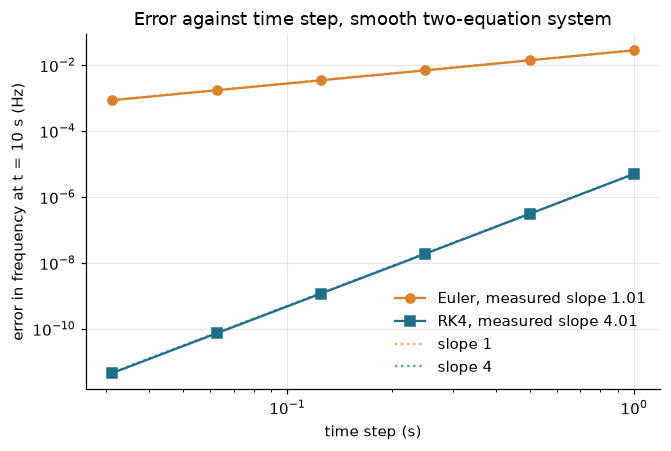

In [8]:
def check_error_order(verbose=True, make_plot=True):
    Ek, D, K, Tg, dP, T = 6000.0, 40.0, 12.0, 2.0, 50.0, 10.0
    p = make_params(1, Ek=Ek, D=D, K=K, Tg=Tg, Pcap=1e9, f_init=F0)       # no limit, start at 50 Hz
    M = 2.0 * Ek / F0
    A = np.array([[-D / M, 1.0 / M], [-K / Tg, -1.0 / Tg]])
    b = np.array([-dP / M, 0.0])
    x_inf = -np.linalg.solve(A, b)
    exact = expm(A * T) @ (np.zeros(2) - x_inf) + x_inf                   # (f - f0, Pg) at time T
    steps = 1.0 / 2.0 ** np.arange(6)                                     # 1, 0.5, ..., 0.03125 s
    errors = {}
    for name, stepper in (("RK4", step_rk4), ("Euler", step_euler)):
        errs = []
        for dt in steps:
            _, y = simulate_smooth(p, -dP, T=T, dt=dt, stepper=stepper)
            errs.append(abs(y[-1, 0, 0] - F0 - exact[0]))
        errors[name] = np.array(errs)
    slope_rk4 = np.polyfit(np.log(steps), np.log(errors["RK4"]), 1)[0]
    slope_euler = np.polyfit(np.log(steps), np.log(errors["Euler"]), 1)[0]
    assert 3.7 < slope_rk4 < 4.3, f"RK4 order {slope_rk4:.2f}"
    assert 0.85 < slope_euler < 1.15, f"Euler order {slope_euler:.2f}"
    if verbose:
        print(f"PASS check 3: measured order RK4 = {slope_rk4:.2f} (theory 4), Euler = {slope_euler:.2f} (theory 1)")
    if make_plot:
        fig, ax = plt.subplots(figsize=(6.2, 4.2))
        ax.loglog(steps, errors["Euler"], "o-", color=ORANGE, label=f"Euler, measured slope {slope_euler:.2f}")
        ax.loglog(steps, errors["RK4"], "s-", color=BLUE, label=f"RK4, measured slope {slope_rk4:.2f}")
        ax.loglog(steps, errors["Euler"][0] * steps, ":", color=ORANGE, alpha=0.7, label="slope 1")
        ax.loglog(steps, errors["RK4"][0] * steps ** 4, ":", color=BLUE, alpha=0.7, label="slope 4")
        ax.set_xlabel("time step (s)"); ax.set_ylabel("error in frequency at t = 10 s (Hz)")
        ax.set_title("Error against time step, smooth two-equation system")
        ax.legend(frameon=False)
        fig.tight_layout(); fig.savefig("figures/verification.png", dpi=160); plt.show()
    return slope_rk4, slope_euler


ORDER_RK4, ORDER_EULER = check_error_order()

### Check 4: energy balance

Multiplying the swing equation by $2E_k/f_0$ and integrating over time gives a conservation statement: the energy that flowed in or out through the power imbalance must equal the change in stored kinetic energy.

$$\int_0^T \Big(u + P_g + P_b - D\,(f - f_{init})\Big)\,dt = \frac{2E_k}{f_0}\big(f(T) - f(0)\big)$$

The left side is integrated from the saved traces with the trapezoid rule (and $u$ as a step function, as the model holds it). This is done for the full model with all event rules active, so it also checks the bookkeeping of the solar losses and the load shedding.

In [9]:
def check_energy(p=None, verbose=True):
    p = make_params(1) if p is None else p
    run = simulate_events(p, T=15.0, keep_trace=True)
    tr = run["trace"]
    f, Pg, Pb, u = tr["f"][:, 0], tr["Pg"][:, 0], tr["Pb"][:, 0], tr["u"][:, 0]
    mid = lambda v: 0.5 * (v[:-1] + v[1:])                                 # trapezoid rule
    imbalance = u[:-1] + mid(Pg) + mid(Pb) - p["D"][0] * (mid(f) - p["f_init"][0])   # [MW]
    energy_in = np.sum(imbalance) * DT                                     # [MW s]
    stored = 2.0 * p["Ek"][0] / p["f0"][0] * (f[-1] - f[0])                # [MW s]
    residual = abs(energy_in - stored) / abs(stored)
    assert residual < 1e-4, f"energy residual {residual:.2e}"
    if verbose:
        print(f"PASS check 4: energy through the imbalance {energy_in:.2f} MW s, change in stored energy "
              f"{stored:.2f} MW s, relative residual {residual:.1e} (tolerance 1e-4)")
    return residual


_ = check_energy()

PASS check 4: energy through the imbalance -579.55 MW s, change in stored energy -579.55 MW s, relative residual 2.8e-07 (tolerance 1e-4)


### Check 5: step-size study of the full model

With the event rules on, an event can only be noticed at the start of a step, so its timing can be late by up to one step. The error of the full model is therefore expected to fall roughly in proportion to the step size (order about 1), not with order 4. The cell measures this against a run with a ten times smaller step, and confirms that the working step of 10 ms is accurate enough.

In [10]:
def check_full_model_order(p=None, verbose=True):
    p = make_params(1) if p is None else p
    T, t_probe = 14.0, (6.0, 9.0, 12.0, 14.0)
    reference = simulate_events(p, T=T, dt=0.001, sample_times=t_probe)["samp_f"][:, 0]
    steps = np.array([0.02, 0.01, 0.005])
    errors = []
    for dt in steps:
        got = simulate_events(p, T=T, dt=dt, sample_times=t_probe)["samp_f"][:, 0]
        errors.append(np.max(np.abs(got - reference)))
    errors = np.array(errors)
    order = np.polyfit(np.log(steps), np.log(errors), 1)[0]
    err_working = errors[list(steps).index(DT)]
    euler = simulate_events(p, T=T, dt=DT, stepper=step_euler, sample_times=t_probe)["samp_f"][:, 0]
    rk4 = simulate_events(p, T=T, dt=DT, sample_times=t_probe)["samp_f"][:, 0]
    assert err_working < 0.02, f"error at the working step is {err_working:.4f} Hz"
    if verbose:
        print("full model, largest error at the probe times against a 1 ms run:")
        for dt, e in zip(steps, errors):
            print(f"   dt = {dt * 1000:4.0f} ms   error = {e:.5f} Hz")
        print(f"   observed order of the full event model = {order:.2f} (expected about 1, not 4)")
        print(f"   Euler and RK4 at the working step differ by {np.max(np.abs(euler - rk4)):.5f} Hz")
        print(f"PASS check 5: error at the working step ({DT * 1000:.0f} ms) = {err_working:.5f} Hz (tolerance 0.02 Hz)")
    return order, err_working


ORDER_FULL, ERR_FULL = check_full_model_order()

full model, largest error at the probe times against a 1 ms run:
   dt =   20 ms   error = 0.00787 Hz
   dt =   10 ms   error = 0.00220 Hz
   dt =    5 ms   error = 0.00182 Hz
   observed order of the full event model = 1.06 (expected about 1, not 4)
   Euler and RK4 at the working step differ by 0.00521 Hz
PASS check 5: error at the working step (10 ms) = 0.00220 Hz (tolerance 0.02 Hz)


### Check 6: statistics helpers

- Wilson interval: for 0 collapses in 10 runs the exact interval is $[0,\; z^2/(N+z^2)] = [0,\, 0.2775]$; for 5 in 10 it is symmetric about 0.5.
- Inverse-transform sampler: over many redraws the mean share at each setting must return the survey shares, and the spread must match the binomial value $\sqrt{p(1-p)/1608}$.

In [11]:
def check_statistics(verbose=True):
    low, high = wilson_interval(0, 10)
    assert low == 0.0 and abs(high - 1.96 ** 2 / (10 + 1.96 ** 2)) < 1e-12
    low5, high5 = wilson_interval(5, 10)
    assert abs((low5 + high5) / 2 - 0.5) < 1e-12
    rng = np.random.default_rng(SEED)
    shares = sample_inverter_shares(4000, rng)
    assert np.allclose(shares.sum(axis=1), 1.0)
    mean_err = np.max(np.abs(shares.mean(axis=0) - SHARES))
    sd_theory = np.sqrt(SHARES * (1 - SHARES) / N_INV)
    sd_ratio = shares.std(axis=0) / sd_theory
    assert mean_err < 3 * sd_theory.max() / np.sqrt(4000) * 1.5
    assert np.all(np.abs(sd_ratio - 1.0) < 0.08)
    if verbose:
        print(f"PASS check 6: Wilson(0 of 10) = [0, {high:.4f}]; sampler mean error {mean_err:.1e}, "
              f"spread / binomial spread = {np.round(sd_ratio, 3)}")


check_statistics()

PASS check 6: Wilson(0 of 10) = [0, 0.2775]; sampler mean error 8.6e-05, spread / binomial spread = [0.996 0.991 1.002 1.002]


## 6. Experiments and results

### 6.1 Calibration against the recorded event

Calibration is done in two steps, with a seeded random search that narrows its search box around the best draws each round.

**Step 1: governor.** The governor equation is driven by the *recorded* frequency, and $K$, $T_g$ and $P_{cap}$ are chosen so that the simulated output of the controlling unit follows its six recorded values. The meter records *electrical* power, which includes the unit's own flywheel effect while the frequency is falling, so the comparison uses

$$P_{unit}(t) = P_g(t) - \frac{2 H_u S_u}{f_0}\frac{df}{dt}$$

with $H_u = 3.45$ s and $S_u = 95$ MVA for the unit [3]. Without this term the same stored energy would be counted twice (once here and once in $E_k$).

**Step 2: system.** With the governor fixed, the stored energy $E_k$, load damping $D$, first solar loss $\Delta P_0$ and relief factor $r$ are chosen to minimise the root-mean-square error (RMSE) against the seven recorded frequency values. $E_k$ is not allowed below the stored energy of the machines known to be running.

In [12]:
def zoom_search(loss, box, rng, n=6000, rounds=3, keep=40):
    """Seeded random search. Each round samples the box uniformly, then shrinks it around the best draws."""
    best_value, best_point = np.inf, None
    for _ in range(rounds):
        draws = {name: rng.uniform(lo, hi, n) for name, (lo, hi) in box.items()}
        value = loss(draws)
        order = np.argsort(value)[:keep]
        if value[order[0]] < best_value:
            best_value, best_point = value[order[0]], {name: draws[name][order[0]] for name in box}
        box = {name: (draws[name][order].min(), draws[name][order].max()) for name in box}
    return best_value, best_point


# ---- Step 1: governor, driven by the recorded frequency -------------------------------------------------
vic = next(u for u in UNITS if u["plant"] == "Victoria")
C_UNIT = 2.0 * float(vic["inertia_constant_s"]) * float(vic["rated_mva"]) / F0     # [MW per Hz/s] flywheel term
f_rec = PchipInterpolator(REC_T, REC_F)                 # smooth curve through the seven recorded points
t_fine = np.arange(0.0, REC_T[-1] + DT / 2, DT)
f_fine, dfdt_fine = f_rec(t_fine), f_rec.derivative()(t_fine)
REC_DPU = REC_PU - REC_PU[0]                            # [MW] recorded rise of the unit's output
idx_rec = np.round(REC_T / DT).astype(int)


def unit_output(K, Tg, Pcap):
    """Simulated electrical output rise of the controlling unit at the recorded times (rows) for each set."""
    Pg = np.zeros_like(K)
    out = np.zeros((len(REC_T), K.size))
    decay = np.exp(-DT / Tg)                            # exact update of the lag for a target held over a step
    for k in range(len(t_fine)):
        if k in idx_rec:
            out[list(idx_rec).index(k)] = Pg - C_UNIT * dfdt_fine[k]
        target = np.minimum(Pcap, K * np.maximum(F0 - f_fine[k], 0.0))
        Pg = target + (Pg - target) * decay
    return out


def governor_loss(d):
    sim = unit_output(d["K"], d["Tg"], d["Pcap"])
    return np.sqrt(np.mean((sim[1:] - REC_DPU[1:, None]) ** 2, axis=0))     # [MW]


rng_cal = np.random.default_rng(SEED)
gov_rmse, gov = zoom_search(governor_loss, {"K": (2.0, 40.0), "Tg": (0.3, 8.0), "Pcap": (15.0, 60.0)}, rng_cal)
CAL_K, CAL_TG, CAL_PCAP = gov["K"], gov["Tg"], gov["Pcap"]
print(f"governor fit: K = {CAL_K:.1f} MW/Hz, Tg = {CAL_TG:.2f} s, Pcap = {CAL_PCAP:.1f} MW, RMSE = {gov_rmse:.1f} MW")
print("   recorded rise [MW]:", REC_DPU[1:].astype(int))
print("   fitted   rise [MW]:", np.round(unit_output(np.array([CAL_K]), np.array([CAL_TG]), np.array([CAL_PCAP]))[1:, 0], 1))
print(f"   (the 2% droop on the unit's rating would allow {float(vic['rated_mva']) / (PAR['governor_droop'] * F0):.0f} MW/Hz; "
      f"the record shows a much slower response)")

# ---- Step 2: system parameters, against the seven recorded frequencies ---------------------------------
EK_FLOOR = sum(float(u["inertia_constant_s"]) * float(u["rated_mva"]) * float(u["units_online"])
               for u in UNITS if u["units_online"])                         # [MW s] machines known to be running
BOX = {"Ek": (EK_FLOOR, 9000.0), "D": (PAR["D_low"], PAR["D_high"]),
       "dP0": (PAR["dP0_low"], PAR["dP0_high"]), "relief": (0.3, 1.0)}
T_FIT = REC_T[-1] + 0.1


def rmse_to_record(p, points=slice(None)):
    run = simulate_events(p, T=T_FIT, sample_times=REC_T)
    return np.sqrt(np.mean((run["samp_f"][points] - REC_F[points, None]) ** 2, axis=0)), run


def system_loss(d):
    return rmse_to_record(make_params(d["Ek"].size, K=CAL_K, Tg=CAL_TG, Pcap=CAL_PCAP, **d))[0]


t_cal = time.time()
cal_rmse, CAL = zoom_search(system_loss, BOX, rng_cal, n=8000, rounds=3)
print(f"\nsystem fit ({time.time() - t_cal:.0f} s): " + ", ".join(f"{k} = {v:.3g}" for k, v in CAL.items()))
P_CAL = make_params(1, K=CAL_K, Tg=CAL_TG, Pcap=CAL_PCAP, **CAL)
best = simulate_events(P_CAL, T=T_END, keep_trace=True, sample_times=REC_T)
sim7 = best["samp_f"][:, 0]
RMSE7 = float(np.sqrt(np.mean((sim7 - REC_F) ** 2)))
RMSE4 = float(np.sqrt(np.mean((sim7[:4] - REC_F[:4]) ** 2)))
print("   time [s]      :", REC_T)
print("   recorded [Hz] :", REC_F)
print("   simulated [Hz]:", np.round(sim7, 2))
print(f"   RMSE on all seven points = {RMSE7:.3f} Hz; on the first four = {RMSE4:.3f} Hz")
T_COLLAPSE_CAL = float(best["t_cross"][47.0][0])
assert RMSE7 < 0.35, "calibration error too large"
assert not np.isnan(T_COLLAPSE_CAL), "the calibrated base case must collapse"
print(f"PASS calibration: RMSE {RMSE7:.3f} Hz < 0.35 Hz and the base case collapses (below 47 Hz at {T_COLLAPSE_CAL:.2f} s)")

governor fit: K = 9.4 MW/Hz, Tg = 0.55 s, Pcap = 24.3 MW, RMSE = 3.2 MW
   recorded rise [MW]: [ 4 18 26 43 41 42]
   fitted   rise [MW]: [ 5.9 17.6 26.3 37.  42.1 46.4]
   (the 2% droop on the unit's rating would allow 95 MW/Hz; the record shows a much slower response)



system fit (10 s): Ek = 6.94e+03, D = 36.1, dP0 = 40.1, relief = 0.422


   time [s]      : [ 0.   5.  10.  15.  16.8 17.8 18.7]
   recorded [Hz] : [50.12 49.51 48.27 47.48 46.07 44.86 43.48]
   simulated [Hz]: [50.12 49.61 48.35 47.27 46.14 44.75 43.65]
   RMSE on all seven points = 0.121 Hz; on the first four = 0.120 Hz
PASS calibration: RMSE 0.121 Hz < 0.35 Hz and the base case collapses (below 47 Hz at 16.25 s)


**Validation against data that were not used in the fit.** The fit used only the seven frequency values from the controlling unit's logger [1]. Two independent sets of measurements are available to test it:

- the disturbance recorder's times for the 49.5 Hz crossing and for each load-shedding stage [2] (the two instruments disagree by up to about 0.6 s at the same frequency, which limits how closely any model can match both);
- the inertia constants and ratings of the generators that were running [3], which give a floor for the stored energy.

event                      recorder [s]   model [s]   difference [s]
frequency reaches 49.5 Hz        4.98        6.95         1.97
load shedding stage I            8.33        9.02         0.69
load shedding stage II           8.83       10.10         1.27
load shedding stage III          9.38       10.79         1.41
load shedding stage IV          10.13       11.64         1.51
load shedding stage V           14.43       13.74        -0.69
rate of fall from 47.5 Hz to 43.5 Hz: recorded 1.3 Hz/s, model 0.79 Hz/s

stored energy: calibrated 6941 MW s; machines known to be running give at least 5290 MW s (ratio 1.31); equivalent H = 9.4 s on 739 MW dispatched
relief factor: calibrated 0.42; reported effectiveness of the scheme about 0.50 [1]
PASS validation: every event time within 1.97 s of the recorder (tolerance 2.5 s)


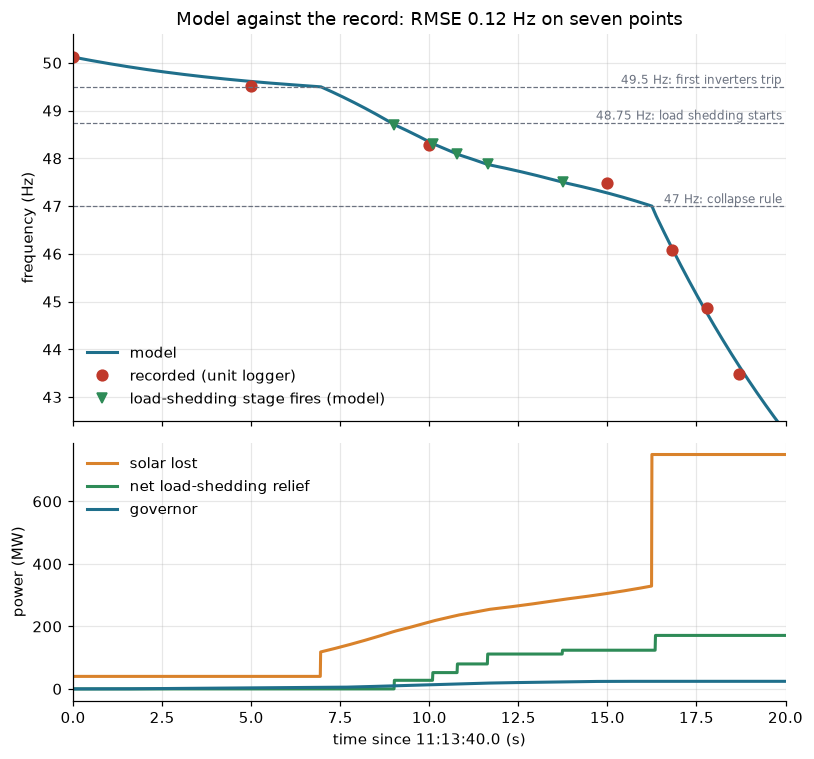

PASS checks 1 to 5 repeated with the calibrated parameters (energy residual 1.7e-07; full-model error at the working step 0.0035 Hz, observed order 1.61)


In [13]:
print("event                      recorder [s]   model [s]   difference [s]")
rows = [("frequency reaches 49.5 Hz", EVENTS["reached_49_5"], float(best["t_cross"][49.5][0]))]
for i, name in enumerate(("stage_I", "stage_II", "stage_III", "stage_IV", "stage_V")):
    rows.append((f"load shedding {name.replace('_', ' ')}", EVENTS[name], float(best["t_fire"][i][0])))
for label, rec, mod in rows:
    print(f"{label:26s} {rec:10.2f} {mod:11.2f} {mod - rec:12.2f}")
LANDMARK_ERR = float(np.max(np.abs([m - r for _, r, m in rows])))
i_a, i_b = np.argmax(best["trace"]["f"][:, 0] < 47.5), np.argmax(best["trace"]["f"][:, 0] < 43.5)
rocof_model = (47.5 - 43.5) / ((i_b - i_a) * DT) if i_b > i_a else float("nan")
print(f"rate of fall from 47.5 Hz to 43.5 Hz: recorded {PAR['rocof_final_recorded']:.1f} Hz/s, model {rocof_model:.2f} Hz/s")
print(f"\nstored energy: calibrated {CAL['Ek']:.0f} MW s; machines known to be running give at least {EK_FLOOR:.0f} MW s "
      f"(ratio {CAL['Ek'] / EK_FLOOR:.2f}); equivalent H = {CAL['Ek'] / PAR['P_dispatched']:.1f} s on 739 MW dispatched")
print(f"relief factor: calibrated {CAL['relief']:.2f}; reported effectiveness of the scheme about {PAR['relief_reported']:.2f} [1]")
assert LANDMARK_ERR < 2.5, "event times are far from the recorder"
print(f"PASS validation: every event time within {LANDMARK_ERR:.2f} s of the recorder (tolerance 2.5 s)")

fig, axes = plt.subplots(2, 1, figsize=(7.5, 7.0), sharex=True, gridspec_kw={"height_ratios": [3, 2]})
ax = axes[0]
ax.plot(best["t"], best["trace"]["f"][:, 0], color=BLUE, lw=2, label="model")
ax.plot(REC_T, REC_F, "o", color=RED, ms=7, label="recorded (unit logger)")
for lv, name in ((49.5, "49.5 Hz: first inverters trip"), (48.75, "48.75 Hz: load shedding starts"), (47.0, "47 Hz: collapse rule")):
    ax.axhline(lv, color=GREY, lw=0.8, ls="--"); ax.text(19.9, lv + 0.06, name, ha="right", fontsize=8, color=GREY)
for i in range(5):
    tf = best["t_fire"][i][0]
    if not np.isnan(tf):
        ax.plot(tf, np.interp(tf, best["t"], best["trace"]["f"][:, 0]), "v", color=GREEN, ms=7,
                label="load-shedding stage fires (model)" if i == 0 else None)
ax.set_ylabel("frequency (Hz)"); ax.set_ylim(42.5, 50.6)
ax.set_title(f"Model against the record: RMSE {RMSE7:.2f} Hz on seven points")
ax.legend(frameon=False, loc="lower left")
ax = axes[1]
ax.plot(best["t"], best["trace"]["lost"][:, 0], color=ORANGE, lw=2, label="solar lost")
ax.plot(best["t"], CAL["relief"] * best["trace"]["shed"][:, 0], color=GREEN, lw=2, label="net load-shedding relief")
ax.plot(best["t"], best["trace"]["Pg"][:, 0], color=BLUE, lw=2, label="governor")
ax.set_xlabel("time since 11:13:40.0 (s)"); ax.set_ylabel("power (MW)"); ax.set_xlim(0, 20)
ax.legend(frameon=False, loc="upper left")
fig.tight_layout(); fig.savefig("figures/calibration.png", dpi=160); plt.show()

# The verification checks are repeated with the calibrated parameters, to confirm nothing broke.
check_exact_solution(verbose=False); check_limits(verbose=False); check_error_order(verbose=False, make_plot=False)
res_cal = check_energy(P_CAL, verbose=False)
order_cal, err_cal = check_full_model_order(P_CAL, verbose=False)
print(f"PASS checks 1 to 5 repeated with the calibrated parameters (energy residual {res_cal:.1e}; "
      f"full-model error at the working step {err_cal:.4f} Hz, observed order {order_cal:.2f})")

### 6.2 Uncertain inputs

One calibrated run is a single guess. The inputs below are not known exactly, so each is given a distribution and the model is run many times.

| Input | Distribution | Why |
|---|---|---|
| First solar loss $\Delta P_0$ | Uniform, 25 to 77 MW | the two sources disagree [1], [2]; nothing favours a value inside the range |
| Stored energy $E_k$ | Uniform, from the floor set by the running machines up to 9,000 MW s | not published; load inertia and unlisted hydro add an unknown amount |
| Load damping $D$ | Uniform, 30 to 60 MW/Hz | 1 to 2% load change per 1% frequency change |
| Relief factor $r$ | Uniform, 0.3 to 1.0 | depends on how much rooftop solar sat on each shed feeder |
| Governor limit $P_{cap}$ | Uniform, fitted value ±20% | only one unit's response is recorded |
| Inverter shares | Redrawn survey of 1,608 inverters (inverse-transform sampling) | a sample, not a census |

Uniform distributions are used wherever only a range is known, because they add no information beyond the range.

**Judging survival.** A run that has not collapsed after 20 s is not necessarily safe: it may simply be falling more slowly. The function `outcome` therefore follows every undecided run further, first to 60 s and then to 300 s, stopping early once every run has either gone under 45 Hz or stopped falling for 5 s. A run counts as a **survivor only if its frequency has stopped falling above 47.0 Hz**. (An early version of this study used the 20 s window alone and wrongly reported that extra inertia prevents the collapse; with the longer window the same runs collapse a few seconds later.)

In [14]:
N_MC = 40000                                           # runs in the main Monte Carlo batch
rng = np.random.default_rng(SEED)                      # the one generator used for all experiments


def draw_inputs(n, rng):
    """Draw n sets of the uncertain inputs."""
    p = make_params(n, K=CAL_K, Tg=CAL_TG)
    p["dP0"] = rng.uniform(PAR["dP0_low"], PAR["dP0_high"], n)
    p["Ek"] = rng.uniform(EK_FLOOR, 9000.0, n)
    p["D"] = rng.uniform(PAR["D_low"], PAR["D_high"], n)
    p["relief"] = rng.uniform(0.3, 1.0, n)
    p["Pcap"] = CAL_PCAP * rng.uniform(0.8, 1.2, n)
    shares = sample_inverter_shares(n, rng)
    p["s1"], p["s2"], p["s3"] = shares[:, 0], shares[:, 1], shares[:, 2]
    return p


def subset(p, mask):
    return {k: v[mask].copy() for k, v in p.items()}


def changed(p, **changes):
    q = {k: v.copy() for k, v in p.items()}
    for k, v in changes.items():
        q[k] = np.broadcast_to(np.asarray(v, dtype=float), q["Ek"].shape).copy()
    return q


HORIZONS = (60.0, 300.0)                               # [s] windows used, in turn, to decide a run


def outcome(p, first=None):
    """Decide every run. Returns (lowest frequency [Hz], still falling after the longest window?).

    Runs are followed in stages: only those that are still falling (and not yet below STOP_BELOW) at the
    end of one window are run again over the next, longer one. `first` can supply a 20 s run already made."""
    windows = HORIZONS
    if first is None:
        first, windows = simulate_events(p, T=HORIZONS[0], stop_when_settled=True), HORIZONS[1:]
    fmin, falling = first["fmin"].copy(), first["falling_end"].copy()
    for window in windows:
        again = falling & (fmin >= STOP_BELOW)
        if not again.any():
            break
        late = simulate_events(subset(p, again), T=window, stop_when_settled=True)
        fmin[again], falling[again] = late["fmin"], late["falling_end"]
    return fmin, falling


def is_collapse(fmin, falling, level=F_COLLAPSE):
    """Collapse = below the level, or still falling after the longest window (it never settled)."""
    return (fmin < level) | falling


t_mc = time.time()
P_MC = draw_inputs(N_MC, rng)
MC = simulate_events(P_MC, T=T_END, sample_times=REC_T)
MC_SECONDS = time.time() - t_mc
FMIN_MC, FALLING_MC = outcome(P_MC, first=MC)
collapsed = is_collapse(FMIN_MC, FALLING_MC)                             # collapse rule: below 47.0 Hz
collapsed46 = is_collapse(FMIN_MC, FALLING_MC, PAR["f_collapse_alt"])    # repeat with 46.0 Hz
print(f"{N_MC} runs in {MC_SECONDS:.1f} s ({MC_SECONDS / N_MC * 1000:.2f} ms per run), seed {SEED}")
print(f"{int((MC['falling_end'] & (MC['fmin'] >= STOP_BELOW)).sum())} runs were undecided at 20 s and were followed further; "
      f"{int(((MC['fmin'] >= F_COLLAPSE) & (FMIN_MC < F_COLLAPSE)).sum())} of them fell below 47 Hz after 20 s and "
      f"{int((FALLING_MC & (FMIN_MC >= F_COLLAPSE)).sum())} were still falling at {HORIZONS[-1]:.0f} s (counted as collapses)")
print("collapse probability over the input ranges (below 47.0 Hz):", describe(collapsed.sum(), N_MC))
print("same with the 46.0 Hz rule                                :", describe(collapsed46.sum(), N_MC))
P_PRIOR = collapsed.mean()

40000 runs in 37.2 s (0.93 ms per run), seed 20250209
9735 runs were undecided at 20 s and were followed further; 3737 of them fell below 47 Hz after 20 s and 0 were still falling at 300 s (counted as collapses)
collapse probability over the input ranges (below 47.0 Hz):  28.2%  [95% CI 27.7% to 28.6%]  (11264 of 40000)
same with the 46.0 Hz rule                                :  28.2%  [95% CI 27.7% to 28.6%]  (11264 of 40000)


### 6.3 Monte Carlo convergence

The collapse probability is an average of 0/1 outcomes, so by the law of large numbers the estimate settles as the number of runs $N$ grows, and its error should fall like $N^{-1/2}$. The left panel shows the running estimate with its Wilson interval. The right panel splits the batch into independent groups of size $N$ and plots the average error of the group estimates; the fitted slope must be close to $-0.5$.

PASS Monte Carlo error falls with slope -0.53 on the log-log plot (theory -0.5)


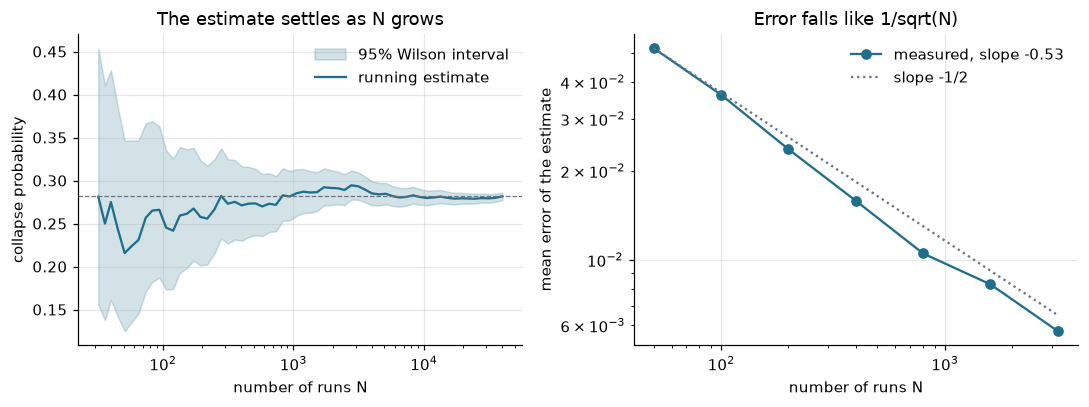

In [15]:
running_n = np.unique(np.round(np.logspace(1.5, np.log10(N_MC), 60)).astype(int))
running_k = np.cumsum(collapsed)[running_n - 1]
lo, hi = wilson_interval(running_k, running_n)
sizes = np.array([50, 100, 200, 400, 800, 1600, 3200])
mean_err = np.array([np.mean(np.abs(collapsed[: (N_MC // s) * s].reshape(-1, s).mean(axis=1) - P_PRIOR)) for s in sizes])
MC_SLOPE = np.polyfit(np.log(sizes), np.log(mean_err), 1)[0]
assert -0.65 < MC_SLOPE < -0.35, f"Monte Carlo error slope {MC_SLOPE:.2f}"
print(f"PASS Monte Carlo error falls with slope {MC_SLOPE:.2f} on the log-log plot (theory -0.5)")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
axes[0].fill_between(running_n, lo, hi, color=BLUE, alpha=0.2, label="95% Wilson interval")
axes[0].plot(running_n, running_k / running_n, color=BLUE, label="running estimate")
axes[0].axhline(P_PRIOR, color=GREY, ls="--", lw=0.8)
axes[0].set_xscale("log"); axes[0].set_xlabel("number of runs N"); axes[0].set_ylabel("collapse probability")
axes[0].set_title("The estimate settles as N grows"); axes[0].legend(frameon=False)
axes[1].loglog(sizes, mean_err, "o-", color=BLUE, label=f"measured, slope {MC_SLOPE:.2f}")
axes[1].loglog(sizes, mean_err[0] * (sizes / sizes[0]) ** -0.5, ":", color=GREY, label="slope -1/2")
axes[1].set_xlabel("number of runs N"); axes[1].set_ylabel("mean error of the estimate")
axes[1].set_title("Error falls like 1/sqrt(N)"); axes[1].legend(frameon=False)
fig.tight_layout(); fig.savefig("figures/monte_carlo_convergence.png", dpi=160); plt.show()

### 6.4 Which inputs drive the answer? (sensitivity)

The 40,000 runs are sorted by each input in turn and cut into five equal groups. If an input matters, the collapse probability changes from group to group; if it does not, the groups look alike. The *swing* of an input is the difference between its highest and lowest group, and the inputs are ranked by it. Error bars are 95% Wilson intervals.

input                               swing in collapse probability   [95% interval]
relief factor of load shedding           81.7%                [80.8% to 82.5%]
load damping                             33.0%                [31.1% to 34.8%]
first solar loss                         24.9%                [23.1% to 26.7%]
share of inverters set at 49.5 Hz         6.0%                [4.0% to 7.9%]
stored energy (inertia)                   1.2%                [0.0% to 3.2%]
governor limit                            0.8%                [0.0% to 2.7%]


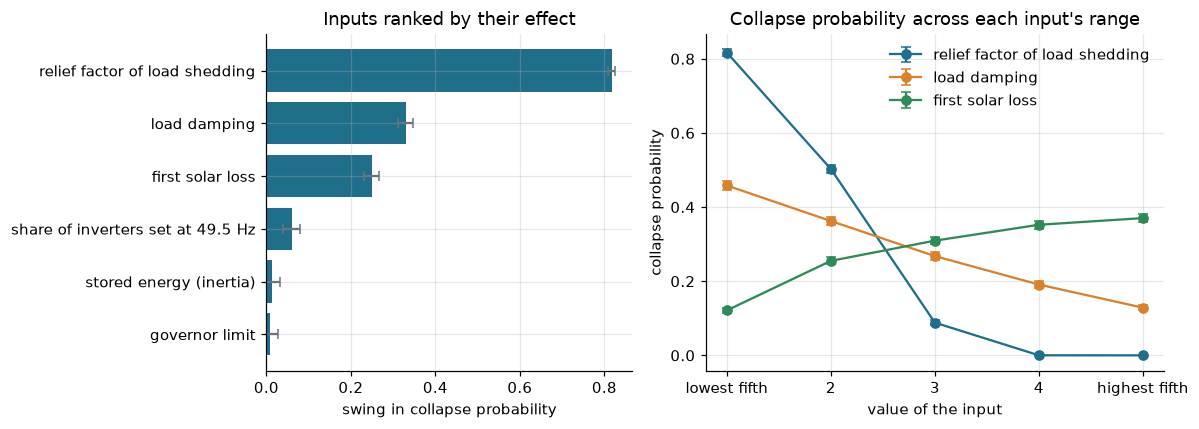

In [16]:
INPUT_LABELS = {"relief": "relief factor of load shedding", "D": "load damping", "dP0": "first solar loss",
                "Ek": "stored energy (inertia)", "Pcap": "governor limit", "s1": "share of inverters set at 49.5 Hz"}
N_BINS = 5
effects = {}
for name in INPUT_LABELS:
    order = np.argsort(P_MC[name])
    groups = np.array_split(order, N_BINS)
    k = np.array([collapsed[g].sum() for g in groups]); n = np.array([len(g) for g in groups])
    lo, hi = wilson_interval(k, n)
    centre = np.array([P_MC[name][g].mean() for g in groups])
    i_max, i_min = np.argmax(k / n), np.argmin(k / n)
    effects[name] = dict(centre=centre, p=k / n, lo=lo, hi=hi, swing=(k / n).max() - (k / n).min(),
                         swing_lo=max(0.0, lo[i_max] - hi[i_min]), swing_hi=hi[i_max] - lo[i_min])
ranked = sorted(effects, key=lambda name: effects[name]["swing"], reverse=True)
print("input                               swing in collapse probability   [95% interval]")
for name in ranked:
    e = effects[name]
    print(f"{INPUT_LABELS[name]:36s}{e['swing']:10.1%}                [{e['swing_lo']:.1%} to {e['swing_hi']:.1%}]")
TOP_INPUT = ranked[0]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.0), gridspec_kw={"width_ratios": [1, 1.25]})
ypos = np.arange(len(ranked))[::-1]
swings = np.array([effects[n]["swing"] for n in ranked])
err = np.array([[effects[n]["swing"] - effects[n]["swing_lo"] for n in ranked], [effects[n]["swing_hi"] - effects[n]["swing"] for n in ranked]])
axes[0].barh(ypos, swings, xerr=err, color=BLUE, ecolor=GREY, capsize=3)
axes[0].set_yticks(ypos); axes[0].set_yticklabels([INPUT_LABELS[n] for n in ranked])
axes[0].set_xlabel("swing in collapse probability"); axes[0].set_title("Inputs ranked by their effect")
for name, colour in zip(ranked[:3], (BLUE, ORANGE, GREEN)):
    e = effects[name]
    axes[1].errorbar(np.arange(1, N_BINS + 1), e["p"], yerr=[e["p"] - e["lo"], e["hi"] - e["p"]], marker="o",
                     color=colour, capsize=3, label=INPUT_LABELS[name])
axes[1].set_xticks(np.arange(1, N_BINS + 1)); axes[1].set_xticklabels(["lowest fifth", "2", "3", "4", "highest fifth"])
axes[1].set_xlabel("value of the input"); axes[1].set_ylabel("collapse probability")
axes[1].set_title("Collapse probability across each input's range"); axes[1].legend(frameon=False)
fig.tight_layout(); fig.savefig("figures/sensitivity.png", dpi=160); plt.show()

### 6.5 Keeping only the runs that look like the real day

The collapse probability in 6.2 answers *"how likely was a collapse, given only the ranges of the inputs?"* The remedies need a different question: *"in a grid that behaves like the one on 9 February, would this fix have worked?"*

For that, an **acceptance-rejection** step keeps only the runs whose simulated frequency lies within a tolerance of the seven recorded values (RMSE at most 0.5 Hz; the two instruments that recorded the event disagree by about that much, because their clocks differ by up to 0.6 s while the frequency is falling at 0.2 to 1.3 Hz/s). The kept runs are a sample of the input combinations that are consistent with the record. Every remedy is then applied to exactly the same kept runs, so the comparisons are paired.

In [17]:
TOLERANCE = 0.5                                         # [Hz] acceptance tolerance on the RMSE to the record
rmse_mc = np.sqrt(np.mean((MC["samp_f"] - REC_F[:, None]) ** 2, axis=0))
keep = rmse_mc <= TOLERANCE
P_DAY = subset(P_MC, keep)
N_DAY = int(keep.sum())
print(f"runs kept: {N_DAY} of {N_MC} ({N_DAY / N_MC:.1%}); all of them collapse: {bool(collapsed[keep].all())}; "
      f"with a tighter 0.35 Hz tolerance {int((rmse_mc <= 0.35).sum())} runs would be kept")
assert N_DAY >= 300, "too few accepted runs for stable estimates"
print("\ninput                              range sampled          kept runs: median [5% to 95%]")
for name in ("relief", "D", "dP0", "Ek", "Pcap"):
    a, b = P_MC[name].min(), P_MC[name].max()
    q5, q50, q95 = np.percentile(P_DAY[name], [5, 50, 95])
    print(f"{INPUT_LABELS[name]:34s} {a:7.4g} to {b:7.4g}      {q50:7.4g} [{q5:.4g} to {q95:.4g}]")

runs kept: 601 of 40000 (1.5%); all of them collapse: True; with a tighter 0.35 Hz tolerance 264 runs would be kept

input                              range sampled          kept runs: median [5% to 95%]
relief factor of load shedding         0.3 to       1       0.4113 [0.312 to 0.5606]
load damping                            30 to      60         41.5 [30.91 to 55.38]
first solar loss                        25 to      77        54.06 [36.73 to 73.6]
stored energy (inertia)               5290 to    9000         7545 [5667 to 8830]
governor limit                       19.46 to   29.19        24.18 [19.97 to 28.5]


### 6.6 Remedies, one at a time

Each row changes one thing and reruns the same input sets.

| Scenario | What changes |
|---|---|
| Day as it happened | nothing |
| Correct inverter settings | every inverter trips at 47 Hz, as prescribed |
| More inertia | stored energy raised by 50% |
| Full reserve responds | governor gain and limit scaled up so the whole 230 MW reserve responds with the same droop and lag |
| Load shedding without rooftop solar | relief factor 1.0, as if shed feeders carried no solar |
| Battery, 50 MW and 100 MW | fast battery, response time 0.25 s |

scenario                              | runs consistent with the record (N = 601)        | full input ranges (N = 1000)
                                      | collapse  [95% Wilson]     46 Hz rule  nadir* | collapse  [95% Wilson]     nadir*
Day as it happened                    |  100.0%  [ 99.4% to 100.0%]   100.0%     nan |   28.3%  [ 25.6% to  31.2%]  48.20
Correct inverter settings             |    0.0%  [  0.0% to   0.6%]     0.0%   49.07 |    0.0%  [  0.0% to   0.4%]  49.17
More inertia (+50%)                   |  100.0%  [ 99.4% to 100.0%]   100.0%     nan |   27.9%  [ 25.2% to  30.8%]  48.22
Full reserve responds                 |    0.0%  [  0.0% to   0.6%]     0.0%   49.63 |    0.0%  [  0.0% to   0.4%]  49.67
Load shedding without rooftop solar   |    0.0%  [  0.0% to   0.6%]     0.0%   48.23 |    0.0%  [  0.0% to   0.4%]  48.24
Battery 50 MW                         |    0.0%  [  0.0% to   0.6%]     0.0%   49.63 |    0.2%  [  0.1% to   0.7%]  49.65
Battery 100 MW            

calibrated case with 50% more inertia: below 47 Hz at 24.91 s instead of 16.25 s


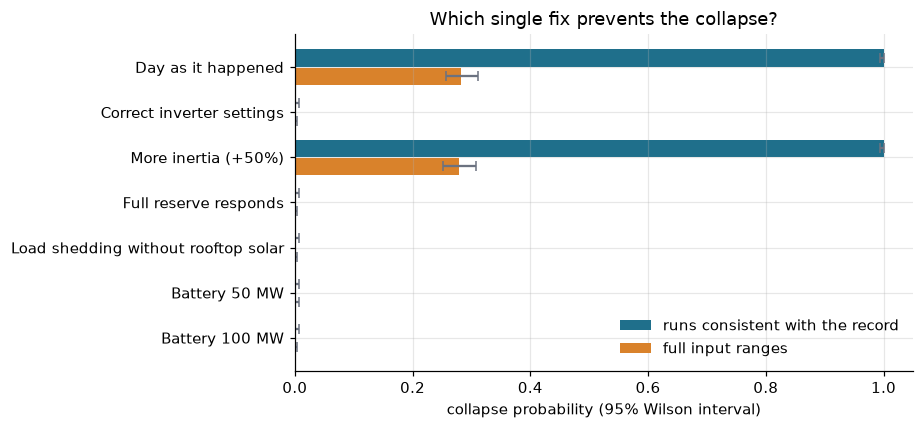

In [18]:
def scenarios(p):
    scale = PAR["spinning_reserve"] / p["Pcap"]
    return [
        ("Day as it happened", p),
        ("Correct inverter settings", changed(p, s1=0.0, s2=0.0, s3=0.0)),
        ("More inertia (+50%)", changed(p, Ek=1.5 * p["Ek"])),
        ("Full reserve responds", changed(p, K=p["K"] * scale, Pcap=PAR["spinning_reserve"])),
        ("Load shedding without rooftop solar", changed(p, relief=1.0)),
        ("Battery 50 MW", changed(p, Pbat=50.0)),
        ("Battery 100 MW", changed(p, Pbat=100.0)),
    ]


def run_scenarios(p):
    table = []
    for name, q in scenarios(p):
        fmin, falling = outcome(q)
        down, down46 = is_collapse(fmin, falling), is_collapse(fmin, falling, PAR["f_collapse_alt"])
        lo, hi = wilson_interval(down.sum(), down.size)
        survivors = fmin[~down]
        table.append(dict(name=name, p=down.mean(), lo=float(lo), hi=float(hi), p46=down46.mean(),
                          nadir=float(np.median(survivors)) if survivors.size else float("nan"), n=down.size))
    return table


N_PRIOR_SCEN = 1000
TABLE_DAY = run_scenarios(P_DAY)                                   # runs consistent with the record
TABLE_PRIOR = run_scenarios(subset(P_MC, np.arange(N_MC) < N_PRIOR_SCEN))   # full input ranges
print(f"{'scenario':38s}| runs consistent with the record (N = {N_DAY})        | full input ranges (N = {N_PRIOR_SCEN})")
print(f"{'':38s}| collapse  [95% Wilson]     46 Hz rule  nadir* | collapse  [95% Wilson]     nadir*")
for a, b in zip(TABLE_DAY, TABLE_PRIOR):
    print(f"{a['name']:38s}| {a['p']:7.1%}  [{a['lo']:6.1%} to {a['hi']:6.1%}] {a['p46']:8.1%}  {a['nadir']:6.2f} "
          f"| {b['p']:7.1%}  [{b['lo']:6.1%} to {b['hi']:6.1%}] {b['nadir']:6.2f}")
print("* median lowest frequency [Hz] of the runs that survive")
slow = simulate_events(changed(P_CAL, Ek=1.5 * P_CAL["Ek"]), T=60.0)
T_COLLAPSE_INERTIA = float(slow["t_cross"][47.0][0])
print(f"calibrated case with 50% more inertia: below 47 Hz at {T_COLLAPSE_INERTIA:.2f} s instead of {T_COLLAPSE_CAL:.2f} s")

fig, ax = plt.subplots(figsize=(8.5, 4.0))
names = [r["name"] for r in TABLE_DAY]
ypos = np.arange(len(names))[::-1]
for table, offset, colour, label in ((TABLE_DAY, 0.2, BLUE, "runs consistent with the record"), (TABLE_PRIOR, -0.2, ORANGE, "full input ranges")):
    p = np.array([r["p"] for r in table])
    err = np.array([[r["p"] - r["lo"] for r in table], [r["hi"] - r["p"] for r in table]])
    ax.barh(ypos + offset, p, height=0.38, xerr=err, color=colour, ecolor=GREY, capsize=3, label=label)
ax.set_yticks(ypos); ax.set_yticklabels(names); ax.set_xlim(0, 1.05)
ax.set_xlabel("collapse probability (95% Wilson interval)"); ax.set_title("Which single fix prevents the collapse?")
ax.legend(frameon=False, loc="lower right")
fig.tight_layout(); fig.savefig("figures/remedies.png", dpi=160); plt.show()

### 6.7 How much solar can the grid carry?

The embedded (mostly rooftop) share of generation was about 50% on the day. Here it is swept from 20% to 70% for the runs consistent with the record, once with the inverter settings as surveyed and once with every inverter set to 47 Hz. When the share changes: the embedded pool and the first loss scale with it; the conventional plant and its stored energy scale with what is left; and shed feeders carry proportionally more or less solar, so the relief factor scales with the conventional share.

inverter settings as surveyed  : collapse probability by share 20%:0% 25%:0% 30%:0% 35%:0% 40%:2% 45%:32% 50%:100% 55%:100% 60%:100% 65%:100% 70%:100%
   largest swept share with the collapse probability surely below 5%: 40%
inverter settings all at 47 Hz : collapse probability by share 20%:0% 25%:0% 30%:0% 35%:0% 40%:0% 45%:0% 50%:0% 55%:0% 60%:0% 65%:0% 70%:0%
   largest swept share with the collapse probability surely below 5%: 70%


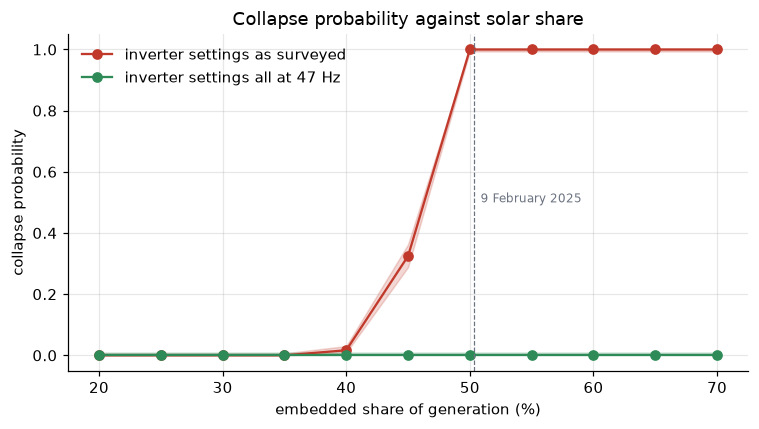

In [19]:
SHARE_DAY = PAR["P_embedded"] / PAR["P_total"]


def with_solar_share(p, share):
    q = {k: v.copy() for k, v in p.items()}
    q["Pemb"] = np.full_like(p["Ek"], share * PAR["P_total"])           # [MW]
    q["dP0"] = p["dP0"] * share / SHARE_DAY                             # [MW]
    q["Ek"] = p["Ek"] * (1.0 - share) / (1.0 - SHARE_DAY)               # [MW s]
    q["relief"] = np.clip(p["relief"] * (1.0 - share) / (1.0 - SHARE_DAY), 0.0, 1.0)
    return q


shares_swept = np.arange(0.20, 0.701, 0.05)
sweep = {"as surveyed": [], "all at 47 Hz": []}
for share in shares_swept:
    q = with_solar_share(P_DAY, share)
    sweep["as surveyed"].append(is_collapse(*outcome(q)).sum())
    sweep["all at 47 Hz"].append(is_collapse(*outcome(changed(q, s1=0.0, s2=0.0, s3=0.0))).sum())
fig, ax = plt.subplots(figsize=(7, 4))
SAFE_SHARE = {}
for (label, counts), colour in zip(sweep.items(), (RED, GREEN)):
    counts = np.array(counts); p = counts / N_DAY
    lo, hi = wilson_interval(counts, N_DAY)
    ax.fill_between(shares_swept * 100, lo, hi, color=colour, alpha=0.2)
    ax.plot(shares_swept * 100, p, "o-", color=colour, label=f"inverter settings {label}")
    safe = shares_swept[hi < 0.05]
    SAFE_SHARE[label] = float(safe.max()) if safe.size else float("nan")
    print(f"inverter settings {label:13s}: collapse probability by share " + " ".join(f"{s:.0%}:{v:.0%}" for s, v in zip(shares_swept, p)))
    print(f"   largest swept share with the collapse probability surely below 5%: {SAFE_SHARE[label]:.0%}")
ax.axvline(SHARE_DAY * 100, color=GREY, ls="--", lw=0.8); ax.text(SHARE_DAY * 100 + 0.5, 0.5, "9 February 2025", color=GREY, fontsize=8)
ax.set_xlabel("embedded share of generation (%)"); ax.set_ylabel("collapse probability")
ax.set_title("Collapse probability against solar share"); ax.legend(frameon=False)
fig.tight_layout(); fig.savefig("figures/solar_share.png", dpi=160); plt.show()

### 6.8 How small a fix is enough? Battery sizing (stretch goal) and the other remedies

A battery with droop control is added: it starts to respond below 49.8 Hz, reaches full power 0.3 Hz lower, and follows its target with a response time $\tau_b$. Grid batteries respond in roughly 0.1 s [10], and fast-response contracts allow up to 0.5 s [7], so both are tested.

**Known-answer check first.** With the governor and events off and a constant loss $\Delta P$ smaller than the battery, the frequency must settle where battery droop plus load damping balance the loss:

$$f_{ss} = \frac{K_b f_b + D f_{init} - \Delta P}{K_b + D}, \qquad K_b = \frac{P_{bat}}{\Delta f_b}$$

and with the battery larger than the loss and a very fast response, the frequency must stay above the first inverter threshold (49.5 Hz).

**Then the sizing.** Bisection finds the smallest battery (response time 0.1 s) for which at least 95% of the runs consistent with the record survive, and the same battery is then tested with a 0.5 s response time. The same bisection is applied to the other remedies, to find the smallest version of each fix that is enough:

- the share of wrongly set inverters that must be reset to 47 Hz;
- the governor response (in MW) that must actually be delivered;
- the relief factor the load-shedding scheme must reach;
- the factor by which the stored energy would have to grow.

PASS battery known-answer check: settles at 49.668900 Hz, formula 49.668900 Hz; lowest frequency 49.669 Hz stays above 49.5 Hz


battery of 36 MW with response time 0.1 s: collapse share 3.8% (95% CI 2.6% to 5.7%)
battery of 36 MW with response time 0.5 s: collapse share 3.8% (95% CI 2.6% to 5.7%)



smallest change that lets at least 95% of the runs consistent with the record survive:
   fast battery [MW]                                36
   share of wrongly set inverters reset to 47 Hz    0.30
   governor response actually delivered [MW]        95.62
   relief factor of the load shedding               0.66
   stored energy multiplied by                      not enough even at the largest value tested (3 times)


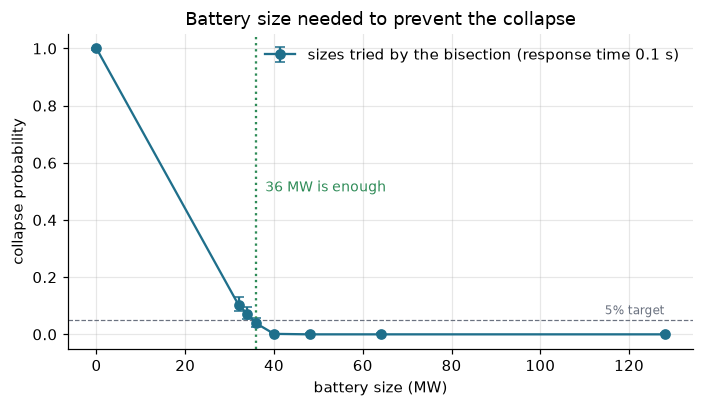

In [20]:
p_b = make_params(1, K=0.0, Ek=CAL["Ek"], D=CAL["D"], Pbat=100.0, tau_b=0.05)       # battery 100 MW > loss 60 MW
dP_test = 60.0
t_b, y_b = simulate_smooth(p_b, -dP_test, T=60.0, dt=DT)
Kb = 100.0 / PAR["battery_df_full"]
f_ss = (Kb * PAR["battery_f_start"] + CAL["D"] * F_INIT - dP_test) / (Kb + CAL["D"])
assert abs(y_b[-1, 0, 0] - f_ss) < 1e-6, "battery steady state differs from the formula"
assert y_b[:, 0, 0].min() > F_HIGH, "an oversized fast battery must hold the frequency above 49.5 Hz"
print(f"PASS battery known-answer check: settles at {y_b[-1, 0, 0]:.6f} Hz, formula {f_ss:.6f} Hz; "
      f"lowest frequency {y_b[:, 0, 0].min():.3f} Hz stays above {F_HIGH} Hz")


def collapse_share(p):
    return float(is_collapse(*outcome(p)).mean())


def smallest_dose(apply, low, high, tol, target=0.05, history=None):
    """Bisection: smallest x in [low, high] for which at most `target` of the runs collapse.

    Returns nan if even the largest value is not enough. `history` collects every (x, share) tried."""
    def share_at(x):
        value = collapse_share(apply(x))
        if history is not None:
            history.append((x, value))
        return value

    if share_at(high) > target:
        return float("nan")
    while high - low > tol:
        mid = 0.5 * (low + high)
        if share_at(mid) <= target:
            high = mid
        else:
            low = mid
    return high


TAU_FAST, TAU_SLOW = PAR["battery_tau_low"], PAR["battery_tau_high"]        # [s] 0.1 and 0.5
tried = [(0.0, 1.0)]                                                         # no battery: every run collapses
BATTERY_MW = smallest_dose(lambda x: changed(P_DAY, Pbat=x, tau_b=TAU_FAST), 0.0, 128.0, tol=2.0, history=tried)
share_fast = collapse_share(changed(P_DAY, Pbat=BATTERY_MW, tau_b=TAU_FAST))
share_slow = collapse_share(changed(P_DAY, Pbat=BATTERY_MW, tau_b=TAU_SLOW))
for tau, share in ((TAU_FAST, share_fast), (TAU_SLOW, share_slow)):
    lo, hi = wilson_interval(round(share * N_DAY), N_DAY)
    print(f"battery of {BATTERY_MW:.0f} MW with response time {tau:.1f} s: collapse share {share:.1%} (95% CI {lo:.1%} to {hi:.1%})")
assert share_fast <= 0.05 and share_slow <= 0.06, "the sized battery must work at both response times"

DOSE = {
    "share of wrongly set inverters reset to 47 Hz": smallest_dose(
        lambda x: changed(P_DAY, s1=(1 - x) * P_DAY["s1"], s2=(1 - x) * P_DAY["s2"], s3=(1 - x) * P_DAY["s3"]), 0.0, 1.0, tol=0.02),
    "governor response actually delivered [MW]": smallest_dose(
        lambda x: changed(P_DAY, K=P_DAY["K"] * x / P_DAY["Pcap"], Pcap=x), 30.0, PAR["spinning_reserve"], tol=4.0),
    "relief factor of the load shedding": smallest_dose(
        lambda x: changed(P_DAY, relief=np.maximum(P_DAY["relief"], x)), 0.3, 1.0, tol=0.02),
    "stored energy multiplied by": smallest_dose(lambda x: changed(P_DAY, Ek=x * P_DAY["Ek"]), 1.0, 3.0, tol=0.05),
}
print("\nsmallest change that lets at least 95% of the runs consistent with the record survive:")
print(f"   {'fast battery [MW]':48s} {BATTERY_MW:.0f}")
for name, value in DOSE.items():
    print(f"   {name:48s} " + ("not enough even at the largest value tested (3 times)" if np.isnan(value) else f"{value:.2f}"))

tried = np.array(sorted(tried))
k_tried = np.round(tried[:, 1] * N_DAY)
lo, hi = wilson_interval(k_tried, N_DAY)
fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.errorbar(tried[:, 0], tried[:, 1], yerr=[tried[:, 1] - lo, hi - tried[:, 1]], fmt="o-", color=BLUE, capsize=3,
            label="sizes tried by the bisection (response time 0.1 s)")
ax.axhline(0.05, color=GREY, ls="--", lw=0.8); ax.text(128, 0.07, "5% target", ha="right", color=GREY, fontsize=8)
ax.axvline(BATTERY_MW, color=GREEN, ls=":"); ax.text(BATTERY_MW + 2, 0.5, f"{BATTERY_MW:.0f} MW is enough", color=GREEN, fontsize=9)
ax.set_xlabel("battery size (MW)"); ax.set_ylabel("collapse probability"); ax.set_title("Battery size needed to prevent the collapse")
ax.legend(frameon=False, loc="upper right")
fig.tight_layout(); fig.savefig("figures/battery.png", dpi=160); plt.show()

### 6.9 Cost of the computation

Running the cases together as arrays is compared with running them one at a time through the same function.

In [21]:
p_small = subset(P_MC, np.arange(N_MC) < 10)
t0 = time.time()
for i in range(10):
    simulate_events(subset(p_small, np.arange(10) == i))
per_run_loop = (time.time() - t0) / 10
per_run_batch = MC_SECONDS / N_MC
SPEEDUP = per_run_loop / per_run_batch
print(f"one run at a time: {per_run_loop * 1000:.1f} ms per run; {N_MC} runs together: {per_run_batch * 1000:.3f} ms per run; "
      f"speed-up {SPEEDUP:.0f} times")

one run at a time: 321.5 ms per run; 40000 runs together: 0.931 ms per run; speed-up 345 times


### 6.10 Reference values for the web demo

The web demo runs the same equations, the same RK4 step and the same 10 ms time step in JavaScript, with the calibrated parameters as its default settings. With those defaults it must reproduce the two numbers printed below.

In [22]:
F_AT_15 = float(np.interp(15.0, best["t"], best["trace"]["f"][:, 0]))
print("calibrated parameters used as the web-demo defaults:")
print("   " + ", ".join(f"{k} = {float(v[0]):.10g}" for k, v in P_CAL.items() if k in ("Ek", "D", "K", "Tg", "Pcap", "dP0", "relief")))
print(f"WEB DEMO REFERENCE 1: frequency falls below 47.0 Hz at t = {T_COLLAPSE_CAL:.2f} s (tolerance 0.02 s)")
print(f"WEB DEMO REFERENCE 2: frequency at t = 15 s is {F_AT_15:.3f} Hz (tolerance 0.005 Hz)")

RUNTIME, CPU_TIME = time.time() - T_START, time.process_time() - CPU_START
print(f"\nwhole notebook: {RUNTIME:.0f} s on the clock, {CPU_TIME:.0f} s of processor time")
print("\nRESULTS AT A GLANCE")
print(f"  verification: RK4 order {ORDER_RK4:.2f}, Euler order {ORDER_EULER:.2f}; full event model order {ORDER_FULL:.2f}; Monte Carlo slope {MC_SLOPE:.2f}")
print(f"  calibration : RMSE {RMSE7:.3f} Hz (7 points), {RMSE4:.3f} Hz (first 4); Ek = {CAL['Ek']:.0f} MW s, D = {CAL['D']:.1f} MW/Hz, "
      f"first loss = {CAL['dP0']:.1f} MW, relief = {CAL['relief']:.2f}")
print(f"  collapse probability over the input ranges: {P_PRIOR:.1%}; most influential input: {INPUT_LABELS[TOP_INPUT]}")
for row in TABLE_DAY:
    print(f"  {row['name']:38s} {row['p']:6.1%}  [{row['lo']:.1%} to {row['hi']:.1%}]")
print(f"  smallest battery: {BATTERY_MW:.0f} MW (works at response times of 0.1 s and 0.5 s)")
for name, value in DOSE.items():
    print(f"  smallest {name}: " + ("not enough" if np.isnan(value) else f"{value:.2f}"))
print(f"  safe solar share (collapse probability below 5%): surveyed settings {SAFE_SHARE['as surveyed']:.0%}, all at 47 Hz {SAFE_SHARE['all at 47 Hz']:.0%}")
assert CPU_TIME < 600, "the notebook must run in under ten minutes"

calibrated parameters used as the web-demo defaults:
   Ek = 6941.303593, D = 36.13398071, K = 9.411158467, Tg = 0.5498645436, Pcap = 24.32644207, dP0 = 40.08340656, relief = 0.4215063921
WEB DEMO REFERENCE 1: frequency falls below 47.0 Hz at t = 16.25 s (tolerance 0.02 s)
WEB DEMO REFERENCE 2: frequency at t = 15 s is 47.274 Hz (tolerance 0.005 Hz)

whole notebook: 237 s on the clock, 185 s of processor time

RESULTS AT A GLANCE
  verification: RK4 order 4.01, Euler order 1.01; full event model order 1.06; Monte Carlo slope -0.53
  calibration : RMSE 0.121 Hz (7 points), 0.120 Hz (first 4); Ek = 6941 MW s, D = 36.1 MW/Hz, first loss = 40.1 MW, relief = 0.42
  collapse probability over the input ranges: 28.2%; most influential input: relief factor of load shedding
  Day as it happened                     100.0%  [99.4% to 100.0%]
  Correct inverter settings                0.0%  [0.0% to 0.6%]
  More inertia (+50%)                    100.0%  [99.4% to 100.0%]
  Full reserve responds    

## 7. Discussion and limitations

**Answer to the question.** In this model the collapse was a power-balance failure, not an inertia failure.

- **Which factor mattered most?** Over the full ranges of the uncertain inputs, the relief factor of the load-shedding scheme changes the collapse probability far more than any other input (section 6.4), followed by load damping and the size of the first solar loss. Stored energy (inertia) and the governor limit hardly change it within their ranges.
- **Which single fix prevents it?** For the runs that reproduce the record (section 6.6), four fixes each prevent the collapse in every run: correct inverter settings, the full spinning reserve responding, load shedding that does not also remove rooftop solar, and a fast battery. Raising inertia by 50% prevents none; it only delays the collapse.
- **How small a fix is enough?** Section 6.8 shows the system was close to balance: resetting about 30% of the wrongly set inverters, a battery of about 36 MW, about 96 MW of governor response instead of the 24 MW delivered, or a relief factor of 0.66 instead of about 0.42 would each have been enough. Tripling the stored energy would not.
- **How much solar can the grid carry?** With the surveyed inverter settings the collapse probability is below 5% only up to an embedded share of about 40%, and it reaches 100% at 50%, the share on the day. With every inverter set to 47 Hz no run collapses anywhere in the range tested, up to 70% (section 6.7).

**Why inertia does not help here.** Inertia sets how fast the frequency moves, not where it ends up. Once the inverters that trip at 49.5 Hz have gone, the lost solar exceeds what load shedding, the governor and load damping give back, so the frequency keeps falling until the 47 Hz inverters trip. More inertia only stretches that fall out in time. An early version of this notebook judged survival at 20 s and wrongly reported that 50% more inertia prevents the collapse; following the same runs for longer shows the collapse at 24.9 s instead of 16.3 s in the calibrated case (section 6.6).

**How far to trust it.** The fitted model reproduces the seven recorded values to 0.12 Hz. Tested against measurements that were not used in the fit, it places the 49.5 Hz crossing about 2 s late and the load-shedding stages 0.7 to 1.5 s from the recorder's times, and its final rate of fall is slower than recorded (0.8 against 1.3 Hz/s). The calibrated stored energy (6,900 MW s) is 1.3 times the floor set by the machines known to be running, which is plausible once the remaining hydro units and the inertia of motor loads are counted. The calibrated relief factor (0.42) agrees with the published statement that the scheme was about half as effective as designed [1].

**Limitations.**

1. **No voltage and no network.** The first solar loss was caused by a voltage dip and is injected by hand; the model cannot say how large it would be for a different fault.
2. **Megawatts are assumed to follow inverter counts.** The inverter logs suggest larger inverters were more likely to have high settings [2], which would make the real cascade stronger than modelled.
3. **The relief factor is one number.** It lumps together the rooftop solar on every shed feeder. Relief and the megawatt split of the inverter settings cannot be told apart from seven data points, so the fit is not unique.
4. **Governor fitted to one unit.** Only one unit's output is published; the response of the other hydro units is inside the fitted values.
5. **Final seconds.** Below about 46 Hz generator protection takes over, which is outside the model.
6. **Seven data points.** The record is short, and the two instruments that captured it disagree by up to 0.6 s.
7. **The model cannot settle the dispute** between the utility and the regulator about responsibility. It can only say which changes would have altered the outcome under its assumptions.

**Next steps.** Use the full disturbance-recorder trace instead of seven points; weight the inverter settings by capacity; model each load-shedding stage with the rooftop capacity on its own feeders [3]; and test the remedies against a larger first loss.

**Web demo reference values.** With its default settings the web demo must reproduce the two numbers printed in section 6.10: the frequency falls below 47.0 Hz at t = 16.25 s (tolerance 0.02 s), and the frequency at t = 15 s is 47.274 Hz (tolerance 0.005 Hz).

## 8. References

1. N. S. Wettasinghe, "Analysis of power system failure occurred on 09 February 2025 in Sri Lanka's power system," *Engineer: J. Inst. Eng. Sri Lanka*, vol. 59, no. 1, pp. 145-155, 2026, doi: 10.4038/engineer.v59i1.7740.
2. Public Utilities Commission of Sri Lanka, "Report of the public hearing held on 05th August 2025 at BMICH, on the total system failure occurred on 09th February 2025," Colombo, Sri Lanka, 2026. [Online]. Available: https://www.pucsl.gov.lk/wp-content/uploads/2026/01/Report-Public-Hearing.pdf
3. Ceylon Electricity Board, "Report of the committee to investigate the total power system failure occurred on 09-02-2025 at 11:14 hrs," Colombo, Sri Lanka, Apr. 2025. [Online]. Available: https://www.pucsl.gov.lk/communications-related-to-total-system-failure-on-09th-february-2025/
4. P. M. Anderson and M. Mirheydar, "A low-order system frequency response model," *IEEE Trans. Power Syst.*, vol. 5, no. 3, pp. 720-729, Aug. 1990, doi: 10.1109/59.65898.
5. T. G. Jathunga, A. H. Wijethunga, and J. B. Ekanayake, "Impact of inertia constant on frequency dynamics of a power system," *Ceylon J. Sci.*, vol. 50, no. 1, pp. 3-10, 2021, doi: 10.4038/cjs.v50i1.7841.
6. S. Adikaram, "Lessons from Sri Lanka's 2025 blackout: Strengthening grid resilience and renewable integration," presented at the Asia Clean Energy Forum, Manila, Philippines, Jun. 2026. [Online]. Available: https://asiacleanenergyforum.adb.org/wp-content/uploads/2026/06/Lessons-from-Sri-Lankas-2025-Blackout.pdf
7. C. MacIver, K. Bell, and M. Nedd, "An analysis of the August 9th 2019 GB transmission system frequency incident," *Electr. Power Syst. Res.*, vol. 199, Art. no. 107444, 2021, doi: 10.1016/j.epsr.2021.107444.
8. E. B. Wilson, "Probable inference, the law of succession, and statistical inference," *J. Amer. Statist. Assoc.*, vol. 22, no. 158, pp. 209-212, 1927, doi: 10.1080/01621459.1927.10502953.
9. Ministry of Environment, Sri Lanka, "Updated nationally determined contributions under the Paris Agreement on climate change," Battaramulla, Sri Lanka, 2021. [Online]. Available: https://unfccc.int/sites/default/files/NDC/2022-06/Amendmend%20to%20the%20Updated%20Nationally%20Determined%20Contributions%20of%20Sri%20Lanka.pdf
10. Aurecon, "Hornsdale Power Reserve: Year 1 technical and market impact case study," 2018. [Online]. Available: https://hornsdalepowerreserve.com.au/wp-content/uploads/2022/12/Aurecon-Hornsdale-Power-Reserve-Impact-Study-year-1.pdf